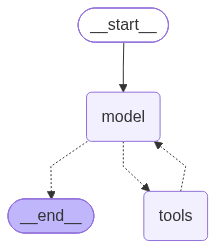

In [34]:
from dotenv import load_dotenv
load_dotenv()

import os
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from pydantic import BaseModel, Field


llm = ChatOpenAI(model="gpt-5-mini", temperature=0, api_key=os.getenv("OPENAI_API_KEY"))

from langchain.tools import tool
from langchain.agents import create_agent

from langchain_community.tools import DuckDuckGoSearchResults
from langchain_community.utilities import DuckDuckGoSearchAPIWrapper


duckduckgo_api = DuckDuckGoSearchAPIWrapper(
    region="wt-wt",
    safesearch="moderate",
    time=None,
    max_results=5,
)

duckduckgo_tool = DuckDuckGoSearchResults(
    api_wrapper=duckduckgo_api,
    name="web_search",
    description=(
        "Search the internet for recent information, "
        "news, current events, software documentation, "
        "technology updates, and current facts. "
        "Use when information may have changed recently. "
        "Input: a search query string. "
        "Returns search results with source links. "
        "Do not use for calculations."
    ),
    max_results=5,
    output_format="string",
)


@tool
def joke_teller() -> str:
    '''
        This tool will be used to tell a joke if needed
    '''
    response = llm.invoke("Tell me a joke like a saiyan prince vegeta!")
    return response.content

agent = create_agent(
    model=llm,
    tools=[duckduckgo_tool, joke_teller],
    system_prompt=(
        "Try to understand the emotion of the input. "
        "If the emotion is so sad or negative, tell a joke. "
        "if there is no emotion, just search what is required. "
        "Searching will be either from the web or from wikipedia. "
    )
)

agent

In [35]:
result = agent.invoke({
    "messages": [
        ("user", "5 bad sides about bangladesh!")
    ]
})

print("\nAgent:", result["messages"][-1].content)


Agent: Here are five commonly cited problems or “bad sides” of Bangladesh, each with a brief explanation:

1. Political instability and restrictions on civil liberties  
   - Frequent political tensions, confrontations between major parties, and reports of limits on press freedom, assembly, and opposition activity have raised concerns about governance and human rights.

2. Corruption and weak rule of law  
   - Corruption and bureaucratic inefficiency can hinder business, public service delivery, and trust in institutions; enforcement of laws is sometimes inconsistent.

3. Poverty, inequality and urban overcrowding  
   - Despite strong economic growth, significant portions of the population still face poverty or precarious informal work. Rapid urbanization has produced severe congestion and large informal settlements, especially in Dhaka.

4. Environmental vulnerability and climate risk  
   - As a low-lying delta, Bangladesh is highly exposed to flooding, cyclones, river erosion, an

In [41]:
streams = agent.stream({
    "messages":[("user", "5 Good sides about Thailand")]
})

for each in streams:
    print(f'{list(each.keys())[0]} Calling')
    print(each)
    print(list(each.values())[-1]["messages"][-1].content)
    print("----------------------\n")

model Calling
{'model': {'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 173, 'prompt_tokens': 250, 'total_tokens': 423, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 128, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-Ef6Q6geJY1hMA7cUt86HhrMbe9vQa', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a192d5-960b-728f-acd3-74a00308ac4d-0', tool_calls=[{'name': 'web_search', 'args': {'query': '5 good sides about Thailand top positive aspects of Thailand reasons to visit Thailand culture food nature beaches cost of living friendly people'}, 'id': 'call_yWeXk8VjOIg